# Linear Regression

In [1]:
# Import the required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## Data Preprocessing

### **Exploring the dataset**

Let's start with loading the training data from the csv into a pandas dataframe



Load the datasets from GitHub. Train dataset has already been loaded for you in df below. To get test dataset use the commented code.

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/cronan03/DevSoc_AI-ML/main/train_processed_splitted.csv')

Let's see what the first 5 rows of this dataset looks like

In [3]:
df.head()

,LotArea,TotalBsmtSF,GrLivArea,GarageArea,PoolArea,OverallCond,Utilities,SalePrice
0,11553,1051,1159,336,0,5,AllPub,158000
1,8400,1052,1052,288,0,5,AllPub,138500
2,8960,1008,1028,360,0,6,AllPub,115000
3,11100,0,930,308,0,7,AllPub,84900
4,15593,1304,2287,667,0,4,AllPub,225000


What are all the features present? What is the range for each of the features along with their mean?

In [4]:
print("Dataset shape:", df.shape)

print("\nFeature names:")
print(df.columns.tolist())

print("\nFeature types:")
print(df.dtypes)

print("\nNumerical feature statistics:")
print(df.select_dtypes(include="number").agg(
    ["min", "max", "mean"]
).T)

print("\nMissing values:")
print(df.isna().sum()[df.isna().sum() > 0])


Dataset shape: (1314, 8)

Feature names:
['LotArea', 'TotalBsmtSF', 'GrLivArea', 'GarageArea', 'PoolArea', 'OverallCond', 'Utilities', 'SalePrice']

Feature types:
LotArea         int64
TotalBsmtSF     int64
GrLivArea       int64
GarageArea      int64
PoolArea        int64
OverallCond     int64
Utilities      object
SalePrice       int64
dtype: object

Numerical feature statistics:
                 min       max           mean
LotArea       1300.0  215245.0   10622.104262
TotalBsmtSF      0.0    6110.0    1058.311263
GrLivArea      334.0    5642.0    1512.900304
GarageArea       0.0    1418.0     473.480213
PoolArea         0.0     738.0       2.643075
OverallCond      1.0       9.0       5.582192
SalePrice    34900.0  755000.0  180795.504566

Missing values:
Series([], dtype: int64)


### **Feature Scaling and One-Hot Encoding**

You must have noticed that some features `(such as Utilities)` are not continuous values.
  
These features contain values indicating different categories and must somehow be converted to numbers so that the computer can understand it. `(Computers only understand numbers and not strings)`
  
These features are called categorical features. We can represent these features as a `One-Hot Representation`
  
  
You must have also noticed that all the other features, each are in a different scale. This can be detremental to the performance of our linear regression model and so we normalize them so that all of them are in the range $[0,1]$

> NOTE: When you are doing feature scaling, store the min/max which you will use to normalize somewhere. This is then to be used at testing time. Try to think why are doing this?

In [5]:
# Do the one-hot encoding here
# Separate features and target
X_train_raw = df.drop(columns=["SalePrice"]).copy()

y_train_raw = df["SalePrice"].to_numpy(
    dtype=float
).reshape(-1, 1)

# Identify numerical and categorical columns
numeric_cols = X_train_raw.select_dtypes(
    include="number"
).columns.tolist()

categorical_cols = X_train_raw.select_dtypes(
    exclude="number"
).columns.tolist()

# Calculate missing-value replacements using training data
numeric_fill_values = (
    X_train_raw[numeric_cols].median().fillna(0)
)

# Fill missing numerical values
X_train_raw[numeric_cols] = (
    X_train_raw[numeric_cols].fillna(numeric_fill_values)
)

# Fill missing categorical values
X_train_raw[categorical_cols] = (
    X_train_raw[categorical_cols].fillna("Missing")
)

# One-hot encode categorical features
train_encoded = pd.get_dummies(
    X_train_raw,
    columns=categorical_cols,
    dtype=float
)

feature_columns = train_encoded.columns.tolist()

print("Features before encoding:", X_train_raw.shape[1])
print("Features after encoding:", train_encoded.shape[1])

Features before encoding: 7
Features after encoding: 8


In [6]:
# Do the feature scaling here
# Calculate scaling values using the training dataset
feature_min = train_encoded.min()

feature_range = (
    train_encoded.max() - feature_min
).replace(0, 1)

# Scale input features into the range [0, 1]
train_scaled = (
    train_encoded - feature_min
) / feature_range

# Also normalize the target (SalePrice)
y_mean = float(y_train_raw.mean())
y_std = float(y_train_raw.std())

if y_std == 0:
    raise ValueError("SalePrice has zero standard deviation")

y_train_normalized = (
    y_train_raw - y_mean
) / y_std

print(train_scaled.head())

print("Normalized target mean:",
      y_train_normalized.mean())

print("Normalized target standard deviation:",
      y_train_normalized.std())

    LotArea  TotalBsmtSF  GrLivArea  GarageArea  PoolArea  OverallCond  \
0  0.047924     0.172013   0.155426    0.236953       0.0        0.500   
1  0.033186     0.172177   0.135268    0.203103       0.0        0.500   
2  0.035804     0.164975   0.130746    0.253879       0.0        0.625   
3  0.045806     0.000000   0.112283    0.217207       0.0        0.750   
4  0.066807     0.213421   0.367935    0.470381       0.0        0.375   

   Utilities_AllPub  Utilities_NoSeWa  
0               1.0               0.0  
1               1.0               0.0  
2               1.0               0.0  
3               1.0               0.0  
4               1.0               0.0  
Normalized target mean: -2.000767216371667e-16
Normalized target standard deviation: 1.0


### **Conversion to NumPy**

Ok so now that we have all preprocessed all the data, we need to convert it to numpy for our linear regression model
  
Assume that our dataset has a total of $N$ datapoints. Each datapoint having a total of $D$ features (after one-hot encoding), we want our numpy array to be of shape $(N, D)$

In our task, we have to predict the `SalePrice`. We will need 2 numpy arrays $

*   List item
*   List item

(X, Y)$. These represent the features and targets respectively

In [7]:
# Convert to numpy array
x = train_scaled.to_numpy(dtype=float)
y = y_train_normalized

print("X shape:", x.shape)
print("Y shape:", y.shape)

print("Missing values in X:", np.isnan(x).sum())
print("Missing values in Y:", np.isnan(y).sum())


X shape: (1314, 8)
Y shape: (1314, 1)
Missing values in X: 0
Missing values in Y: 0


## Linear Regression formulation
  
We now have our data in the form we need. Let's try to create a linear model to get our initial (Really bad) prediction


Let's say a single datapoint in our dataset consists of 3 features $(x_1, x_2, x_3)$, we can pose it as a linear equation as follows:
$$ y = w_1x_1 + w_2x_2 + w_3x_3 + b $$
Here we have to learn 4 parameters $(w_1, w_2, w_3, b)$
  
  
Now how do we extend this to multiple datapoints?  
  
  
Try to answer the following:
- How many parameters will we have to learn in the cae of our dataset? (Don't forget the bias term)
- Form a linear equation for our dataset. We need just a single matrix equation which correctly represents all the datapoints in our dataset
- Implement the linear equation as an equation using NumPy arrays (Start by randomly initializing the weights from a standard normal distribution)

In [8]:
rng = np.random.default_rng(42)

# Small random initial weights
w = 0.01 * rng.standard_normal(
    (1, x.shape[1])
)

# Initial bias
b = 0.0

# Initial predictions
y_pred = x @ w.T + b

print("Number of weights:", w.size)
print("Total parameters including bias:", w.size + 1)
print("Prediction shape:", y_pred.shape)

Number of weights: 8
Total parameters including bias: 9
Prediction shape: (1314, 1)


How well does our model perform? Try comparing our predictions with the actual values

In [9]:
initial_predictions = x @ w.T + b

initial_loss = np.mean(
    (y - initial_predictions) ** 2
)

print("Initial MSE:", initial_loss)

print("\nActual prices (first 5):")
print((y[:5] * y_std + y_mean).round().flatten())

print("\nInitial predicted prices (first 5):")
print(
    (initial_predictions[:5] * y_std + y_mean)
    .round()
    .flatten()
)

Initial MSE: 0.9978275484994075

Actual prices (first 5):
[158000. 138500. 115000.  84900. 225000.]

Initial predicted prices (first 5):
[180526. 180486. 180401. 180372. 180917.]


### **Learning weights using gradient descent**

So these results are really horrible. We need to somehow update our weights so that it correclty represents our data. How do we do that?

We must do the following:
- We need some numerical indication for our performance, for this we define a Loss Function ( $\mathscr{L}$ )
- Find the gradients of the `Loss` with respect to the `Weights`
- Update the weights in accordance to the gradients: $W = W - \alpha\nabla_W \mathscr{L}$

Lets define the loss function:
- We will use the MSE loss since it is a regression task. (Specify the assumptions we make while doing so as taught in the class).
- Implement this loss as a function. (Use numpy as much as possible)

In [10]:
def mse_loss_fn(y_true, y_pred):
    errors = y_pred - y_true
    squared_errors = errors ** 2
    return float(np.mean(squared_errors))

Calculate the gradients of the loss with respect to the weights (and biases). First write the equations down on a piece of paper, then proceed to implement it

In [11]:
def get_gradients(y_true, y_pred, W, b, X):
    """
    Calculates the gradients for the MSE loss function with respect to the weights (and bias)

    Args:
        y_true: The true values of the target variable (SalePrice in our case)
        y_pred: The predicted values of the target variable using our model (W*X + b)

        W: The weights of the model
        b: The bias of the model
        X: The input features

    Returns:
        dW: The gradients of the loss function with respect to the weights
        db: The gradients of the loss function with respect to the bias
    """
    m = X.shape[0]

    errors = y_pred - y_true

    dW = (2 / m) * (errors.T @ X)

    db = float((2 / m) * np.sum(errors))

    return dW, db

Update the weights using the gradients

In [12]:
def update(weights, bias, gradients_weights, gradients_bias, lr):
    """
    Updates the weights (and bias) using the gradients and the learning rate

    Args:
        weights: The current weights of the model
        bias: The current bias of the model

        gradients_weights: The gradients of the loss function with respect to the weights
        gradients_bias: The gradients of the loss function with respect to the bias

        lr: The learning rate

    Returns:
        weights_new: The updated weights of the model

    """
    weights_new = weights - lr * gradients_weights

    bias_new = bias - lr * gradients_bias

    return weights_new, bias_new

Put all these together to find the loss value, its gradient and finally updating the weights in a loop. Feel free to play around with different learning rates and epochs
  
> NOTE: The code in comments are just meant to be used as a guide. You will have to do changes based on your code

In [13]:
NUM_EPOCHS = 1000
LEARNING_RATE = 2e-2

losses = []

for epoch in range(NUM_EPOCHS):
    y_pred = x @ w.T + b
    loss = mse_loss_fn(y, y_pred)
    losses.append(loss)
    dw, db = get_gradients(y, y_pred, w, b, x)
    w, b = update(w, b, dw, db, LEARNING_RATE)


Now use matplotlib to plot the loss graph

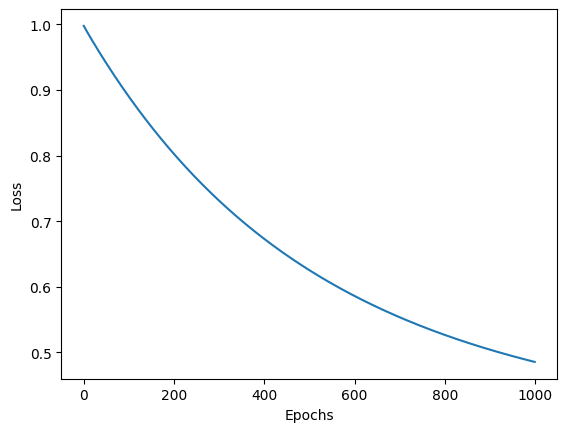

In [14]:
plt.plot(losses)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()

### **Testing with test data**

Load and apply all the preprocessing steps used in the training data for the testing data as well. Remember to use the **SAME** min/max values which you used for the training set and not recalculate them from the test set. Also mention why we are doing this.

To load test data from GitHub, use the code below.


In [15]:
# Load test dataset
df_test = pd.read_csv(
    "https://raw.githubusercontent.com/cronan03/DevSoc_AI-ML/main/test_processed_splitted.csv"
)

print("Test dataset shape:", df_test.shape)

# Separate features and actual sale prices
X_test_raw = df_test.drop(
    columns=["SalePrice"]
).copy()

y_test_raw = df_test["SalePrice"].to_numpy(
    dtype=float
).reshape(-1, 1)

# Match the original training feature columns
X_test_raw = X_test_raw.reindex(
    columns=X_train_raw.columns
)

# Fill missing values using TRAINING values
X_test_raw[numeric_cols] = (
    X_test_raw[numeric_cols].fillna(numeric_fill_values)
)

X_test_raw[categorical_cols] = (
    X_test_raw[categorical_cols].fillna("Missing")
)

# Apply the same one-hot encoding approach
test_encoded = pd.get_dummies(
    X_test_raw,
    columns=categorical_cols,
    dtype=float
)

# Match exactly the columns used in training
test_encoded = test_encoded.reindex(
    columns=feature_columns,
    fill_value=0
)

print("Encoded test shape:", test_encoded.shape)

Test dataset shape: (146, 8)
Encoded test shape: (146, 8)


Using the weights learnt above, predict the values in the test dataset. Also answer the following questions:
- Are the predictions good?
- What is the MSE loss for the testset
- Is the MSE loss for testing greater or lower than training
- Why is this the case

In [16]:
# Use the original TRAINING min/range values
test_scaled = (
    test_encoded - feature_min
) / feature_range

# Convert to numpy
x_test = test_scaled.to_numpy(dtype=float)

# Normalize targets using TRAINING statistics
y_test = (y_test_raw - y_mean) / y_std

print("Training X shape:", x.shape)
print("Testing X shape:", x_test.shape)

print("Training Y shape:", y.shape)
print("Testing Y shape:", y_test.shape)

print("Missing values in X test:", np.isnan(x_test).sum())
print("Missing values in Y test:", np.isnan(y_test).sum())

Training X shape: (1314, 8)
Testing X shape: (146, 8)
Training Y shape: (1314, 1)
Testing Y shape: (146, 1)
Missing values in X test: 0
Missing values in Y test: 0


In [17]:
print(
    "Same feature columns:",
    test_encoded.columns.tolist() == feature_columns
)

print("Train feature count:", x.shape[1])
print("Test feature count:", x_test.shape[1])

Same feature columns: True
Train feature count: 8
Test feature count: 8


In [18]:
# Predict normalized sale prices
y_pred_test = x_test @ w.T + b

# Measure testing loss in normalized units
loss_test = mse_loss_fn(y_test, y_pred_test)

# Calculate final training loss for comparison
loss_train = mse_loss_fn(
    y,
    x @ w.T + b
)

# Convert predictions back to original price units
y_pred_test_original = (
    y_pred_test * y_std + y_mean
)

# Measure error in original sale-price units
rmse_original = np.sqrt(
    np.mean((y_pred_test_original - y_test_raw) ** 2)
)

print("Final training MSE:", loss_train)
print("Test MSE:", loss_test)
print("Test RMSE in original price units:", rmse_original)

Final training MSE: 0.4853679352691642
Test MSE: 0.8002888697704515
Test RMSE in original price units: 69314.31524483871


In [19]:
rng = np.random.default_rng(42)

idx = rng.choice(
    x_test.shape[0],
    size=min(5, x_test.shape[0]),
    replace=False
)

predicted_prices = (
    y_pred_test_original[idx]
    .round()
    .astype(int)
    .flatten()
)

actual_prices = (
    y_test_raw[idx]
    .round()
    .astype(int)
    .flatten()
)

print("Predicted SalePrice:", predicted_prices.tolist())
print("Actual SalePrice:   ", actual_prices.tolist())

print("\nFinal Train MSE:", loss_train)
print("Test MSE:", loss_test)

Predicted SalePrice: [189023, 291422, 183280, 157665, 152412]
Actual SalePrice:    [175000, 625000, 202500, 119000, 164900]

Final Train MSE: 0.4853679352691642
Test MSE: 0.8002888697704515
